<a href="https://colab.research.google.com/github/erickcorrea3092/AZH_ACE_QSARMODEL/blob/main/1_ChEMBERTa_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine learning su aplicación en Biología

__Inteligencia Artificial Aplicada al Análisis de Datos Biológicos__

_MeIA_

`2025`

Adaptado para los estudiantes del L-9 de Síntesis de Fármacos
UMIEZ, FES Zaragoza de la
UNAM

## Cómo el aprendizaje automático (Machine Learning) ayuda al descubrimiento de fármacos

El aprendizaje automático (ML) y la inteligencia artificial (IA) están revolucionando el descubrimiento de fármacos al acelerar los procesos, reducir los costos y mejorar la precisión. A continuación se muestran aplicaciones clave en diferentes etapas de desarrollo:

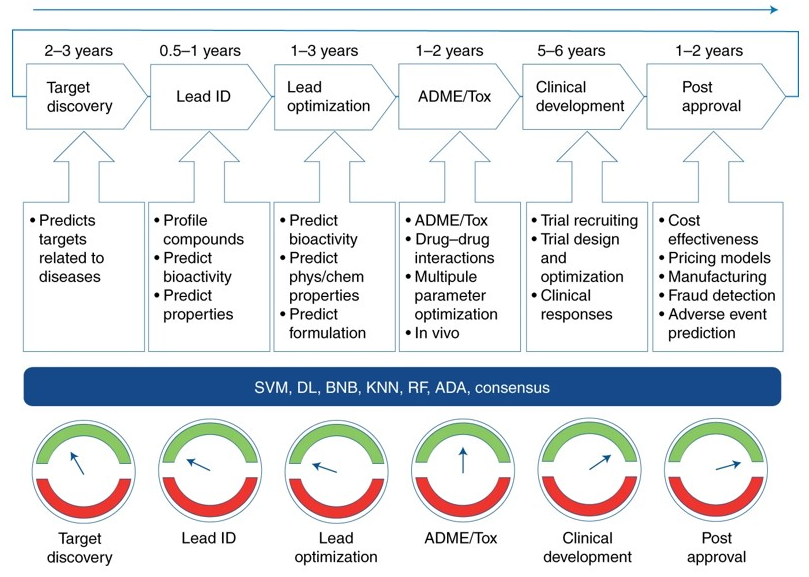

Fonte: Ekins, S.; et al. __Exploiting machine learning for end-to-end drug discovery and development__. Nat. Mater. 2019, 18 (5), 435–441.

## Objetivo: entrenar un modelo para predecir posibles inhibidores de la acetilcolinesterasa (objetivo de la enfermedad de Alzheimer)

Para conseguirlo seguiremos estos pasos:

1. Obtener un conjunto de datos de bioactividad de ChEMBL (https://www.ebi.ac.uk/chembl/);

2. Realizar un preprocesamiento de los datos;

3. Entrenar un modelo basado en descriptores moleculares;

4. Entrenar un modelo basado en huellas dactilares;

5. Entrenar un modelo basado en ChEMBERTa;

6. Finalmente, compararemos la precisión entre ellos.

Entonces, primero, accedamos a la base de datos ChEMBL:

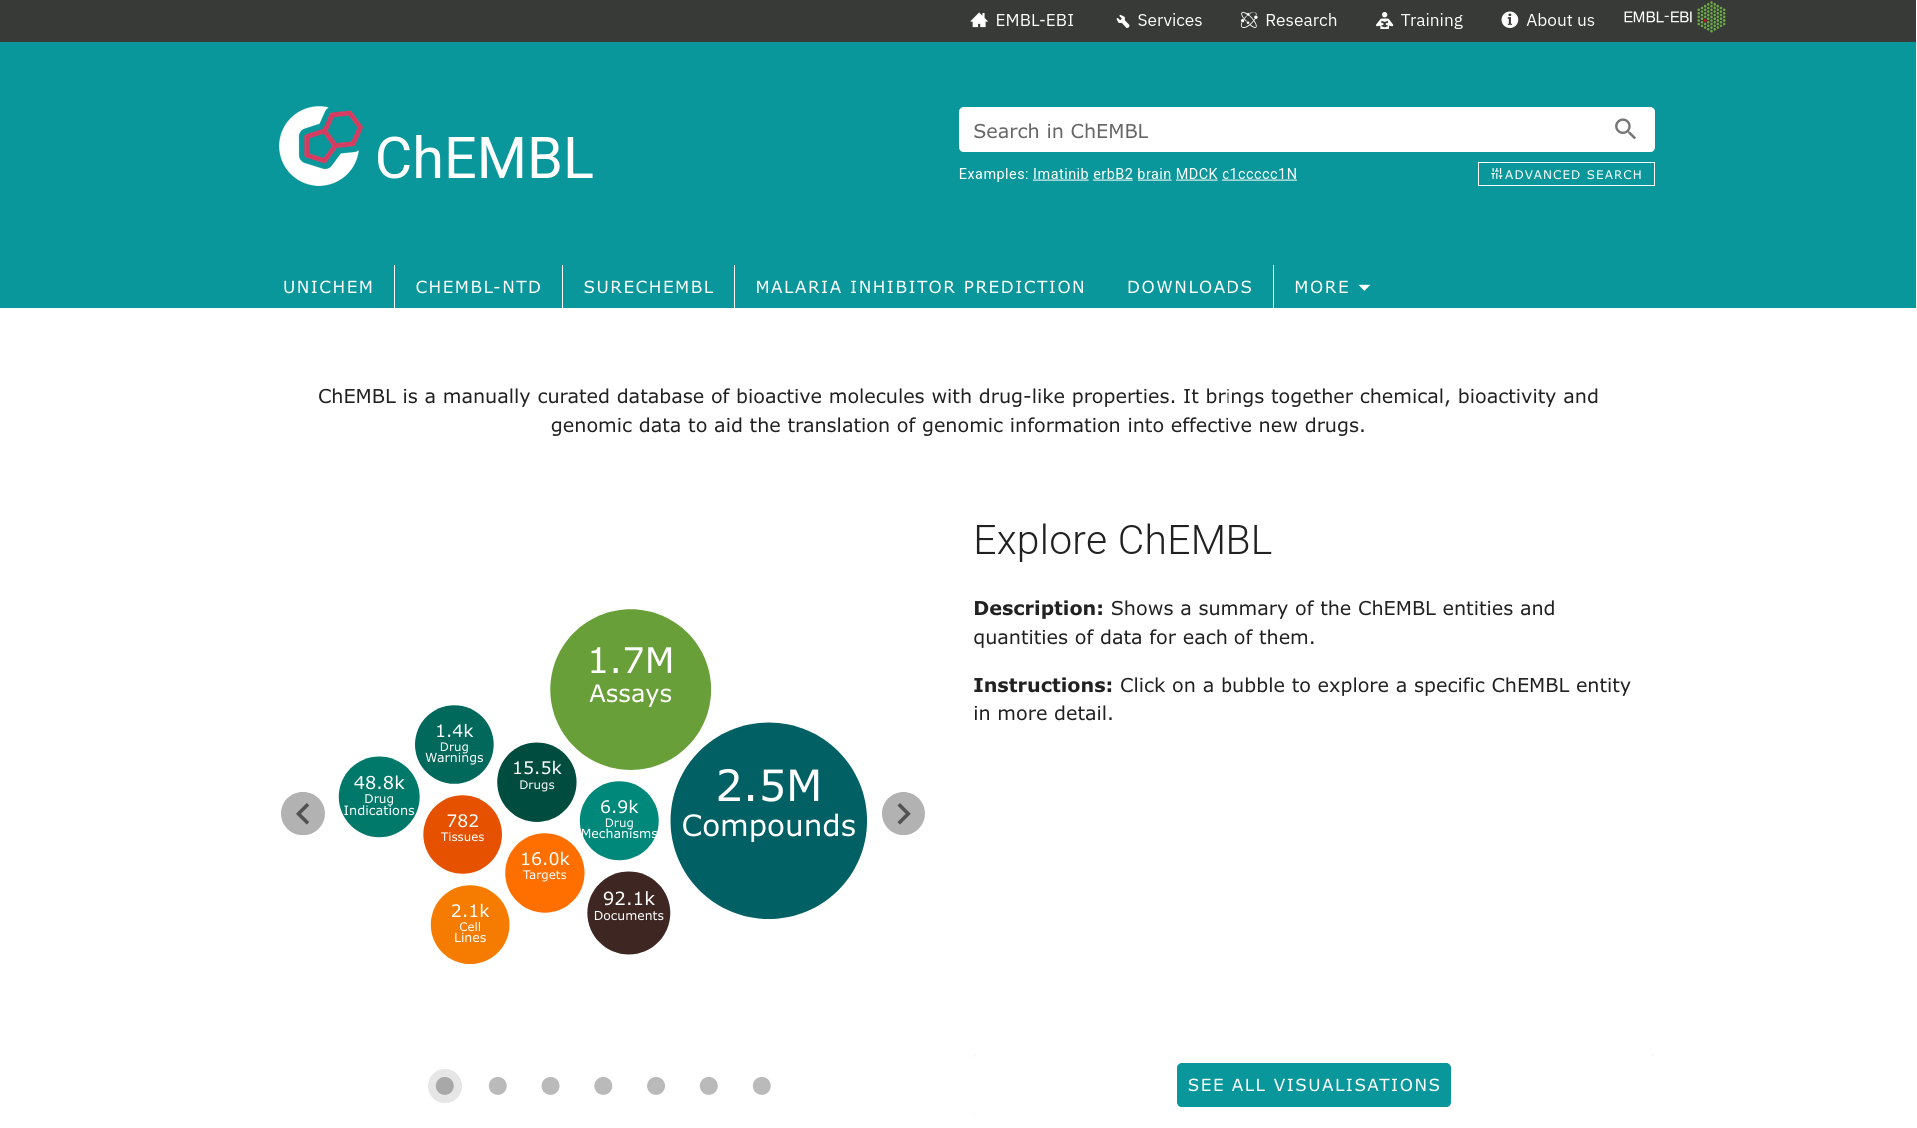

En la pantalla de búsqueda, escriba "acetilcolinesterase". En la pestaña Objetivos, seleccione la acetilcolinesterasa del organismo _Homo sapiens_.

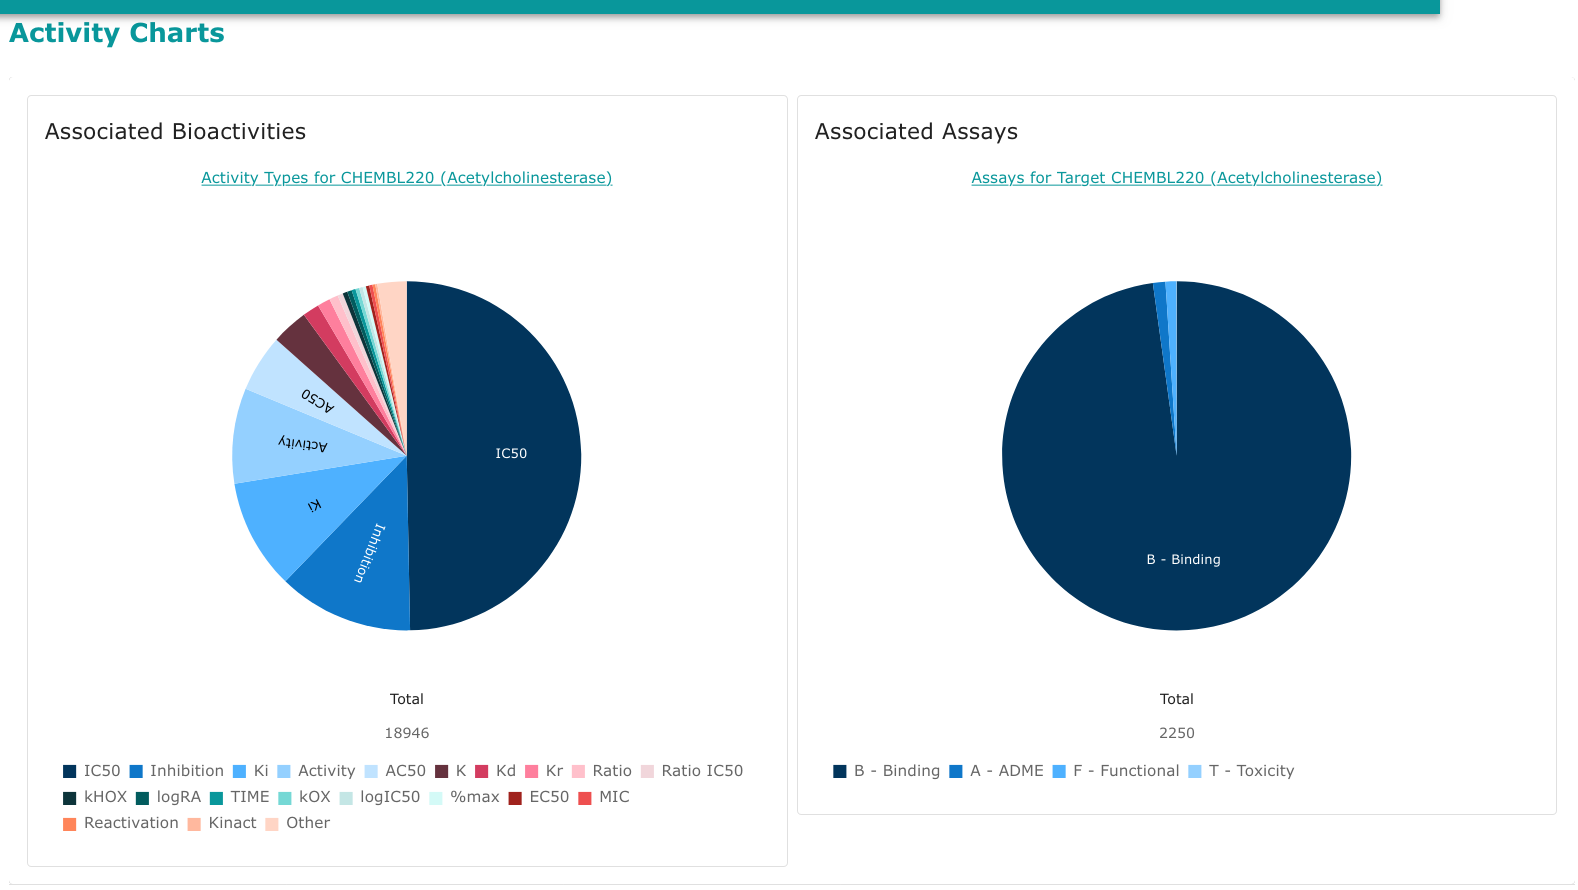

Para esta prueba obtendremos únicamente los datos de IC50, totalizando 9.415 registros de bioactividad. Haremos clic en el apartado del gráfico correspondiente a IC50, y luego veremos una pantalla como la que se muestra a continuación.

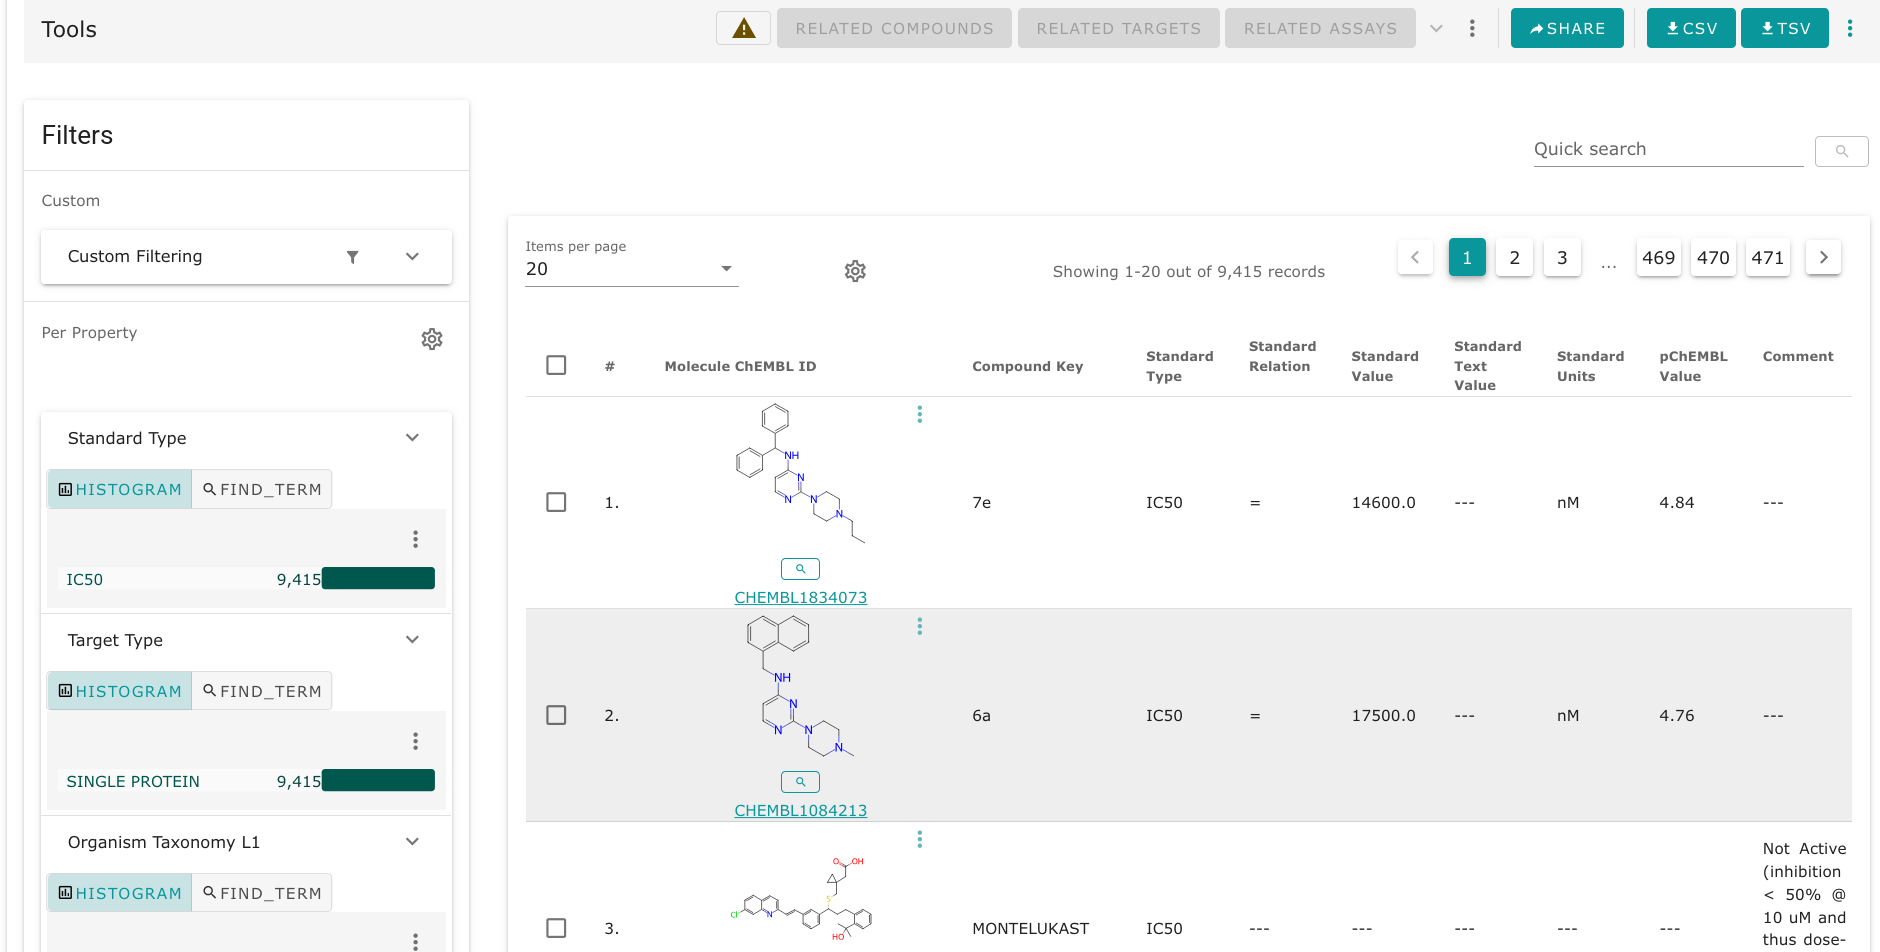

Con un click sobre el ícono de `CSV` se pueden descargar los datos. Se renombrará el archivo `Ache_activity_IC50.csv`.

# Antecedentes

In [1]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
a=False
if a == True:
  with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install --upgrade --force-reinstall numpy
      pbar.update(33)
      !pip install --upgrade --force-reinstall pandas
      pbar.update(33)
      !pip install --upgrade --force-reinstall mordred
      pbar.update(34)

# Importamos

In [2]:
# Exportamos la librerías
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install torch
      !pip install rdkit
      !pip install transformers
      !pip install molplotly
      !pip install seaborn
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [3]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)

      #from mordred import Calculator, descriptors
      #from tqdm.auto import tqdm, trange
      from matplotlib import pyplot as plt

      pbar.update(50)

      from rdkit.ML.Cluster import Butina
      from rdkit import DataStructs
      from rdkit.Chem import PandasTools
      pbar.update(30)
      ! pip install dash==3.2.0
      pbar.update(20)

  0%|          | 0/100 [00:00<?, ?it/s]

In [4]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      import numpy as np
      import pandas as pd
      from rdkit import Chem
      from rdkit.Chem import AllChem
      from rdkit.ML.Descriptors import MoleculeDescriptors
      from rdkit.Chem import Descriptors
      from rdkit import DataStructs
      from rdkit.Chem import rdMolDescriptors
      from rdkit.Chem.Descriptors import MolWt
      from rdkit.Chem.Descriptors import MolLogP
      from rdkit.Chem.Descriptors import NumHAcceptors
      from rdkit.Chem.Descriptors import NumHDonors
      from rdkit.Chem.Descriptors import MolLogP
      from rdkit.Chem import Lipinski
      from rdkit.Chem import QED
      from rdkit.Chem import MolSurf
      from IPython.display import SVG # to use Scalar Vector Graphics (SVG) not bitmaps, for cleaner lines
      from rdkit.Chem import Draw # to draw molecules
      from rdkit.Chem.Draw import IPythonConsole # to draw inline in iPython
      from rdkit.Chem import rdDepictor  # to generate 2D depictions of molecules
      from rdkit.Chem.Draw import rdMolDraw2D # to draw 2D molecules using vectors
      import matplotlib.pyplot as plt
      import seaborn as sns
      from sklearn.ensemble import RandomForestClassifier
      from sklearn import metrics
      from sklearn.metrics import confusion_matrix, classification_report
      import molplotly
      import plotly.express as px
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

# Funciones

In [5]:
def calc_metrics(labels_test, test_probs, threshold = 0.5):
    scores = [1 if x>=threshold else 0 for x in test_probs]
    auc = metrics.roc_auc_score(labels_test, test_probs, multi_class="ovr")
    kappa = metrics.cohen_kappa_score(labels_test,scores)
    confusion = metrics.confusion_matrix(labels_test,scores, labels=list(set(labels_test)))
    print('thresh: %.2f, kappa: %.3f, AUC test-set: %.3f'%(threshold, kappa, auc))
    print(confusion)
    print(metrics.classification_report(labels_test,scores,digits=3))
    return

In [6]:
def standardize_mol(mol, verbose=False):
    """Standardize the RDKit molecule, select its parent molecule, uncharge it,
    then enumerate all the tautomers.
    If verbose is true, an explanation of the steps and structures of the molecule
    as it is standardized will be output."""
    # Follows the steps from:
    #  https://github.com/greglandrum/RSC_OpenScience_Standardization_202104/blob/main/MolStandardize%20pieces.ipynb
    # as described **excellently** (by Greg Landrum) in
    # https://www.youtube.com/watch?v=eWTApNX8dJQ -- thanks JP!

    from rdkit.Chem.MolStandardize import rdMolStandardize
    # removeHs, disconnect metal atoms, normalize the molecule, reionize the molecule
    clean_mol = rdMolStandardize.Cleanup(mol)
    if verbose:
        print('Remove Hs, disconnect metal atoms, normalize the molecule, reionize the molecule:')
        draw_mol_with_SVG(clean_mol)

    # if many fragments, get the "parent" (the actual mol we are interested in)
    parent_clean_mol = rdMolStandardize.FragmentParent(clean_mol)
    if verbose:
        print('Select the "parent" fragment:')
        draw_mol_with_SVG(parent_clean_mol)

    # try to neutralize molecule
    uncharger = rdMolStandardize.Uncharger() # annoying, but necessary as no convenience method exists
    uncharged_parent_clean_mol = uncharger.uncharge(parent_clean_mol)
    if verbose:
        print('Neutralize the molecule:')
        draw_mol_with_SVG(uncharged_parent_clean_mol)

    # Note: no attempt is made at reionization at this step
    # nor ionization at some pH (RDKit has no pKa caculator);
    # the main aim to to represent all molecules from different sources
    # in a (single) standard way, for use in ML, catalogues, etc.
    te = rdMolStandardize.TautomerEnumerator() # idem
    taut_uncharged_parent_clean_mol = te.Canonicalize(uncharged_parent_clean_mol)
    if verbose:
        print('Enumerate tautomers:')
        draw_mol_with_SVG(taut_uncharged_parent_clean_mol)
    assert taut_uncharged_parent_clean_mol != None

    if verbose: print("smile_stand:", Chem.MolToSmiles(taut_uncharged_parent_clean_mol))
    return taut_uncharged_parent_clean_mol


def standardize_smiles(smiles, verbose=False):
  """Standardize the SMILES string, select its parent molecule, uncharge it,
    then enumerate all the tautomers."""
  if verbose: print(smiles)
  std_mol = standardize_mol(Chem.MolFromSmiles(smiles), verbose=verbose)
  return Chem.MolToSmiles(std_mol)


def draw_mol_with_SVG(mol, molSize=(450,150)):
    """Use SVG to draw an RDKit molecule, mol."""
    mc = Chem.Mol(mol.ToBinary())
    if not mc.GetNumConformers():
        rdDepictor.Compute2DCoords(mc) # Compute 2D coordinates
    # Initialize the drawer with the size
    drawer = rdMolDraw2D.MolDraw2DSVG(molSize[0],molSize[1])
    drawer.DrawMolecule(mc) # Draw the molcule
    drawer.FinishDrawing()
    svg = drawer.GetDrawingText() # Get the SVG string
    display(SVG(svg.replace('svg:',''))) # Fix the SVG string and display

In [7]:
def to_numpyarray_to_list(desc):
    arr = np.zeros((1,))
    DataStructs.ConvertToNumpyArray(desc, arr)
    return arr.tolist()

def calcula_fp1(dataframe):
    d={}
    c=0
    for x in dataframe:

        mol = Chem.MolFromSmiles(x)
        fp1 = rdMolDescriptors.GetMorganFingerprintAsBitVect(mol, 20, nBits=2048)
        FP_as_BitVect = to_numpyarray_to_list(fp1)
        d['result{}'.format(c)] = FP_as_BitVect
        c+=1
    df = pd.DataFrame(d).transpose()
    return df

#Cargamos datos

In [8]:
#from google.colab import drive
#drive.mount('/content/drive')
#df=pd.read_csv('/content/drive/MyDrive/MeIA/MeIA_Bioinformatica/ChEMBERTA/Ache_activity_IC50.csv', sep=";")
#df

In [9]:
!gdown --id 1bmNQrSMLWYwxIBhE2eFXWagHY_RafKCH
df=pd.read_csv('Ache_activity_IC50.csv', sep=";")
#df

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1bmNQrSMLWYwxIBhE2eFXWagHY_RafKCH
To: /content/Ache_activity_IC50.csv
100% 5.40M/5.40M [00:00<00:00, 40.9MB/s]


In [10]:
#instalaci[on de el ';'''''';;;'ññññññññññññññ''''''el teclado de latinoamérica es lo mejor del mundo

In [11]:
#df.head(90)

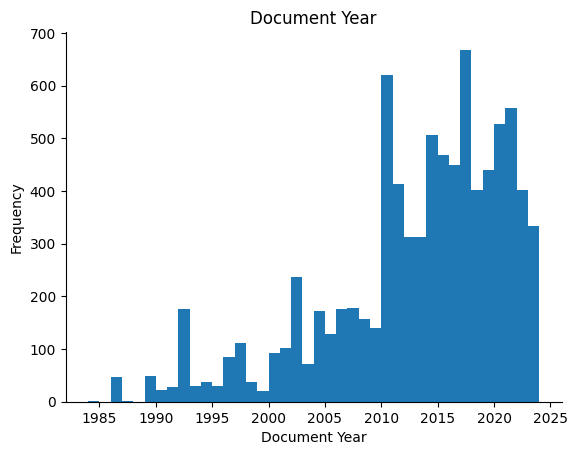

In [12]:
from matplotlib import pyplot as plt
df['Document Year'].plot(kind='hist', bins=40, title='Document Year')
plt.xlabel('Document Year')
plt.ylabel('Frequency')
plt.gca().spines[['top', 'right',]].set_visible(False)

In [13]:
# prompt: repite el histograma con plotly

import plotly.express as px

fig = px.histogram(df, x='Document Year', nbins=40, title='Document Year')
fig.update_layout(xaxis_title='Document Year', yaxis_title='Frequency')
fig.show()

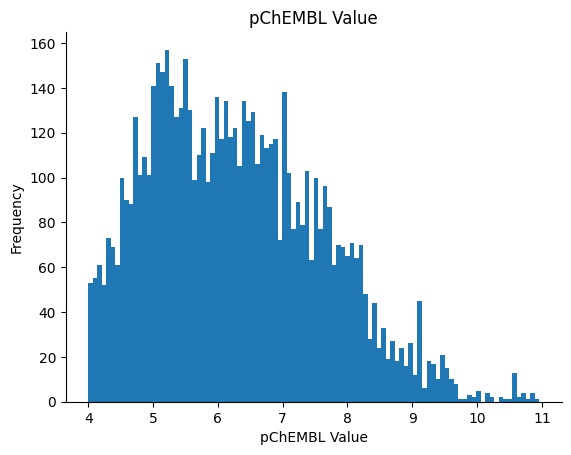

In [14]:
#from matplotlib import pyplot as plt
df['pChEMBL Value'].plot(kind='hist', bins=100, title='pChEMBL Value')
plt.xlabel('pChEMBL Value')
plt.ylabel('Frequency')
plt.gca().spines[['top', 'right',]].set_visible(False)

In [15]:
df

,Molecule ChEMBL ID,Molecule Name,Molecule Max Phase,Molecular Weight,#RO5 Violations,AlogP,Compound Key,Smiles,Standard Type,Standard Relation,...,Document ChEMBL ID,Source ID,Source Description,Document Journal,Document Year,Cell ChEMBL ID,Properties,Action Type,Standard Text Value,Value
0,CHEMBL345905,NaN,NaN,243.35,0.0,2.77,1B,CN1CCC(C[C@H]2Cc3ccccc3C2=O)CC1,IC50,'=',...,CHEMBL1126158,1,Scientific Literature,J Med Chem,1992.0,NaN,NaN,NaN,NaN,7.700
1,CHEMBL263322,NaN,NaN,271.40,0.0,3.55,10,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1,IC50,'=',...,CHEMBL1126158,1,Scientific Literature,J Med Chem,1992.0,NaN,NaN,NaN,NaN,1.500
2,CHEMBL338492,NaN,NaN,208.28,0.0,2.12,35,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1,IC50,'=',...,CHEMBL1130277,1,Scientific Literature,J Med Chem,1997.0,NaN,NaN,NaN,NaN,5.273
3,CHEMBL93936,NaN,NaN,405.54,0.0,4.51,1j,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1,IC50,'=',...,CHEMBL1127437,1,Scientific Literature,J Med Chem,1994.0,NaN,NaN,NaN,NaN,0.800
4,CHEMBL440185,NaN,NaN,236.27,0.0,2.09,8 (table I),COc1cc2c(c(OC)c1OC)C(=O)C(C)C2,IC50,'=',...,CHEMBL1126157,1,Scientific Literature,J Med Chem,1992.0,NaN,NaN,NaN,NaN,7.880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9410,CHEMBL636,RIVASTIGMINE,4.0,250.34,0.0,2.76,Rivastigmine,CCN(C)C(=O)Oc1cccc([C@H](C)N(C)C)c1,IC50,'=',...,CHEMBL4433202,1,Scientific Literature,Eur J Med Chem,2019.0,NaN,NaN,NaN,NaN,1.900
9411,CHEMBL659,GALANTAMINE,4.0,287.36,0.0,1.85,Galantamine,COc1ccc2c3c1O[C@H]1C[C@@H](O)C=C[C@@]31CCN(C)C2,IC50,'=',...,CHEMBL3769338,1,Scientific Literature,Medchemcomm,2015.0,NaN,NaN,NaN,NaN,2.600
9412,CHEMBL269538,HARMINE,1.0,212.25,0.0,3.03,9,COc1ccc2c(c1)[nH]c1c(C)nccc12,IC50,'=',...,CHEMBL5252550,1,Scientific Literature,Eur J Med Chem,2018.0,NaN,NaN,INHIBITOR,NaN,11.300
9413,CHEMBL113,CAFFEINE,4.0,194.19,0.0,-1.03,1,Cn1c(=O)c2c(ncn2C)n(C)c1=O,IC50,'=',...,CHEMBL5223081,1,Scientific Literature,J Med Chem,2021.0,NaN,NaN,INHIBITOR,NaN,5.100


In [16]:
# prompt: busca si en df en la columna Molecule Name busca si se encuentra la benextramine

# Verificar si la columna 'Molecule Name' contiene la subcadena 'Benextramine'
contiene_benextramine = df['Molecule Name'].str.contains('BENEXTRAMINE', na=False).any()

if contiene_benextramine:
    print("La subcadena 'Benextramine' se encuentra en la columna 'Molecule Name'.")
else:
    print("La subcadena 'Benextramine' NO se encuentra en la columna 'Molecule Name'.")

# Opcional: mostrar las filas que contienen 'Benextramine'
filas_con_benextramine = df[df['Molecule Name'].str.contains('Benextramine', na=False)]
if not filas_con_benextramine.empty:
    print("\nFilas que contienen 'Benextramine':")
filas_con_benextramine

La subcadena 'Benextramine' se encuentra en la columna 'Molecule Name'.


,Molecule ChEMBL ID,Molecule Name,Molecule Max Phase,Molecular Weight,#RO5 Violations,AlogP,Compound Key,Smiles,Standard Type,Standard Relation,...,Document ChEMBL ID,Source ID,Source Description,Document Journal,Document Year,Cell ChEMBL ID,Properties,Action Type,Standard Text Value,Value


In [17]:
# prompt: con plotly haz una gráfica de dispersión entre pChEMBL Value vs Document Year

import plotly.express as px

fig = px.scatter(df, x="Document Year", y="pChEMBL Value",
                  title="pChEMBL Value vs Document Year",
                 width=1400, height=800)
#fig.show()

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size
fig.update_layout(hoverlabel_font_size=20)

app_marker = molplotly.add_molecules(fig=fig,
                                     df=df,
                                     smiles_col='Smiles',
                                   #  title_col='Molecule ChEMBL ID',
                                     #color_col="pChEMBL Value",
                                     caption_cols=['Document Journal', 'Molecule Name'],
                                     fontsize=20, width=220)

# Assuming df_d is already created as in your provided code
#plt.figure(figsize=(10, 6))  # Adjust figure size as needed
#sns.histplot(df_d['Cluster_number'], kde=True)  # kde=True adds a kernel density estimate
#plt.title('Histogram of Cluster Number')
#plt.xlabel('Cluster Number')
#plt.ylabel('Frequency')

#fig.show()
app_marker.run(port=8060)

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

# Preprocesado

El primer paso de preprocesamiento que realizaremos es conservar solo los datos donde la relación estándar tiene un valor exacto. Para hacer esto, crearemos un nuevo marco de datos que contenga solo estos registros.

In [18]:
# Filtra linhas onde "Standard Relation" é IGUAL a "="
resultado = df[df["Standard Relation"] == "'='"]
#resultado

In [19]:
#Ahora, verifiquemos si faltan valores (NaN) en la columna SMILES.
resultado["Smiles"].isna().any()

np.True_

In [20]:
# Removendo todas as linhas onde 'Smiles' é NaN
resultado = resultado.dropna(subset=['Smiles'])
#resultado

En algunos casos, es posible que la unidad de medida en la columna __Unidades estándar__ no esté estandarizada. En general, la escala es nM. Comprobemos si hay alguna entrada donde el valor no sea nM.

In [21]:
resultado_non_NM=resultado[resultado["Standard Units"] != "nM"]
#resultado_non_NM['Standard Units']
resultado_non_NM.shape

(33, 48)

Podemos ver que hay 33 entradas en las que los valores no están estandarizados. Esto representa aproximadamente el 0,45% de nuestro conjunto de datos. Teniendo en cuenta que se trata de una cantidad muy pequeña, podemos eliminar estas entradas.

__Sin embargo__: Si el número de puntos de datos no estandarizados es demasiado grande, la recomendación es escribir ecuaciones para estandarizar la unidad de medida de los valores de bioactividad.

In [22]:
# Filtra apenas as linhas onde "Standard Units" é IGUAL a "nM"
resultado = resultado[resultado["Standard Units"] == "nM"]
resultado.shape

(7250, 48)

In some cases, there may be duplicate molecules. Therefore, we will remove duplicate molecules based on the Smiles. But first, let's check how many duplicate entries we have:

In [23]:
# Mostra as linhas duplicadas (baseadas em "Smiles")
duplicatas = resultado[resultado.duplicated(subset=['Smiles'], keep=False)]
len(duplicatas)

1964

It’s possible that the same molecule (duplicate) was tested in different assays, resulting in different inhibition values. In this case, I suggest evaluating other parameters to decide which data point to remove. For simplicity, we will keep the first occurrence.

In [24]:
# Removendo as entradas onde "Smiles" está duplicado (mantém a primeira ocorrência)
resultado = resultado.drop_duplicates(subset=['Smiles'])
resultado.columns

Index(['Molecule ChEMBL ID', 'Molecule Name', 'Molecule Max Phase',
       'Molecular Weight', '#RO5 Violations', 'AlogP', 'Compound Key',
       'Smiles', 'Standard Type', 'Standard Relation', 'Standard Value',
       'Standard Units', 'pChEMBL Value', 'Data Validity Comment', 'Comment',
       'Uo Units', 'Ligand Efficiency BEI', 'Ligand Efficiency LE',
       'Ligand Efficiency LLE', 'Ligand Efficiency SEI', 'Potential Duplicate',
       'Assay ChEMBL ID', 'Assay Description', 'Assay Type', 'BAO Format ID',
       'BAO Label', 'Assay Organism', 'Assay Tissue ChEMBL ID',
       'Assay Tissue Name', 'Assay Cell Type', 'Assay Subcellular Fraction',
       'Assay Parameters', 'Assay Variant Accession', 'Assay Variant Mutation',
       'Target ChEMBL ID', 'Target Name', 'Target Organism', 'Target Type',
       'Document ChEMBL ID', 'Source ID', 'Source Description',
       'Document Journal', 'Document Year', 'Cell ChEMBL ID', 'Properties',
       'Action Type', 'Standard Text Value', 'V

# Análisis Descriptivo de Datos

Para este ejercicio realizaremos una tarea de clasificación, es decir, predecir si una molécula es o no un inhibidor de la acetilcolinesterasa.

Un punto importante a considerar al construir modelos de IA es evaluar la distribución entre clases en el conjunto de entrenamiento. Hacemos esto para evitar que el modelo se sobreajuste a una clase, lo que le impediría generalizar bien las predicciones.

Dado que el objetivo de este ejercicio es predecir si una molécula es inhibidora o no inhibidora, necesitamos definir un umbral para la clasificación de inhibidores basado en el valor IC50.

Consideraremos un buen inhibidor aquel que tenga un valor de IC50 inferior a 500 nM.

In [25]:
resultado.loc[resultado['Standard Value'] > 501, 'Activity'] = 0 #inactives
resultado.loc[resultado['Standard Value'] <= 500, 'Activity'] = 1

<div style="background-color: #e6f3ff; padding: 10px; border: 1px solid #0077cc; border-radius: 5px;">
    <strong>📌 SUPER IMPORTANTE:</strong>  
    La <strong>estandarización</strong> es un paso importante en el procesamiento de moléculas. Este paso implica diversas operaciones, como hacer explícitos los átomos de hidrógeno, eliminar metales, sales y tautómeros, entre otras.
</div>

In [26]:
resultado = resultado.reset_index(drop=True) #vamos criar um novo index
smiles_ache = []

for i in range(len(resultado)):
    smiles_ache.append(resultado["Smiles"][i])

In [27]:
resultado.shape

(5829, 49)

In [28]:
resultado

,Molecule ChEMBL ID,Molecule Name,Molecule Max Phase,Molecular Weight,#RO5 Violations,AlogP,Compound Key,Smiles,Standard Type,Standard Relation,...,Source ID,Source Description,Document Journal,Document Year,Cell ChEMBL ID,Properties,Action Type,Standard Text Value,Value,Activity
0,CHEMBL345905,NaN,NaN,243.35,0.0,2.77,1B,CN1CCC(C[C@H]2Cc3ccccc3C2=O)CC1,IC50,'=',...,1,Scientific Literature,J Med Chem,1992.0,NaN,NaN,NaN,NaN,7.700,1.0
1,CHEMBL263322,NaN,NaN,271.40,0.0,3.55,10,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1,IC50,'=',...,1,Scientific Literature,J Med Chem,1992.0,NaN,NaN,NaN,NaN,1.500,1.0
2,CHEMBL338492,NaN,NaN,208.28,0.0,2.12,35,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1,IC50,'=',...,1,Scientific Literature,J Med Chem,1997.0,NaN,NaN,NaN,NaN,5.273,0.0
3,CHEMBL93936,NaN,NaN,405.54,0.0,4.51,1j,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1,IC50,'=',...,1,Scientific Literature,J Med Chem,1994.0,NaN,NaN,NaN,NaN,0.800,1.0
4,CHEMBL440185,NaN,NaN,236.27,0.0,2.09,8 (table I),COc1cc2c(c(OC)c1OC)C(=O)C(C)C2,IC50,'=',...,1,Scientific Literature,J Med Chem,1992.0,NaN,NaN,NaN,NaN,7.880,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5824,CHEMBL11298,SERINE,3.0,105.09,0.0,-1.61,Serine,N[C@@H](CO)C(=O)O,IC50,'=',...,1,Scientific Literature,J Nat Prod,2023.0,NaN,TIME = 0.3333 hr,INHIBITOR,NaN,38.310,0.0
5825,CHEMBL2234538,NaN,NaN,389.50,0.0,4.94,A10,CCOC(=O)c1c(C)nc2nc3c(c(N)c2c1-c1ccc(C)cc1)CCCCC3,IC50,'=',...,1,Scientific Literature,Med Chem Res,2012.0,NaN,NaN,NaN,NaN,4.890,0.0
5826,CHEMBL4536838,NaN,NaN,624.78,2.0,5.39,"106a; Ref 123, Cpd 8",COc1ccc2[nH]cc(CCNC(=O)CN(CCC3CCN(Cc4ccccc4)CC...,IC50,'=',...,1,Scientific Literature,Bioorg Med Chem,2019.0,NaN,NaN,NaN,NaN,30.700,1.0
5827,CHEMBL151763,NaN,NaN,250.34,0.0,2.76,Rivastigmine,CCN(C)C(=O)Oc1cccc(C(C)N(C)C)c1,IC50,'=',...,1,Scientific Literature,Bioorg Med Chem,2014.0,NaN,NaN,NaN,NaN,35.200,0.0


In [29]:
df_info = resultado[['Molecule ChEMBL ID','pChEMBL Value', 'Molecule Name']].copy() # Seleccionamos algunas columnas desde data
df_info.head(5)

,Molecule ChEMBL ID,pChEMBL Value,Molecule Name
0,CHEMBL345905,8.11,NaN
1,CHEMBL263322,8.82,NaN
2,CHEMBL338492,5.27,NaN
3,CHEMBL93936,9.10,NaN
4,CHEMBL440185,7.88,NaN


In [30]:
#smiles_ache[24]

Tenga en cuenta que si usa la bandera `verbose = True`, mostrará la estructura de las moléculas y la estandarización que se está realizando en la pantalla. Sin embargo, esta bandera no debe usarse con muchas moléculas ya que hará que el programa sea aún más lento.

In [31]:
#standardize_smiles(smiles_ache[1000], verbose = True)

In [32]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      smiles_ache_stand = []
      pbar.update(10)
      for i in range(len(smiles_ache)):
        #standardize_smiles(smiles_ache[i])
        smiles_ache_stand.append(standardize_smiles(smiles_ache[i]))
      pbar.update(90)

  0%|          | 0/100 [00:00<?, ?it/s]

In [33]:
print(len(smiles_ache), len(smiles_ache_stand))

5829 5829


Podemos verificar que se realizó la estandarización de todas las moléculas. Dado que este proceso puede llevar mucho tiempo dependiendo de la cantidad de moléculas a estandarizar, la recomendación es guardar los SMILES estandarizados y cargar el archivo solo al entrenar los modelos.

In [34]:
SMILES_STAND_ACHE = pd.DataFrame(smiles_ache_stand)
SMILES_STAND_ACHE.to_csv('smiles_stand_ache_no_duplicates.csv', sep=';')

In [35]:
SMILES_STAND_ACHE

,0
0,CN1CCC(CC2Cc3ccccc3C2=O)CC1
1,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1
2,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1
3,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1
4,COc1cc2c(c(OC)c1OC)C(=O)C(C)C2
...,...
5824,NC(CO)C(=O)O
5825,CCOC(=O)c1c(C)nc2nc3c(c(N)c2c1-c1ccc(C)cc1)CCCCC3
5826,COc1ccc2[nH]cc(CCNC(=O)CN(CCC3CCN(Cc4ccccc4)CC...
5827,CCN(C)C(=O)Oc1cccc(C(C)N(C)C)c1


In [36]:
descritors = {'QED':[],'MolWt':[],'LogP':[],'HAC':[], 'RB':[], 'TPSA':[],'HBA':[],'HDB':[]}

In [37]:
for i in range(len(smiles_ache_stand)):
    m = Chem.MolFromSmiles(smiles_ache_stand[i])
    descritors['QED'].append(QED.default(m))
    descritors['MolWt'].append(MolWt(m))
    descritors['LogP'].append(MolLogP(m))
    descritors['HAC'].append(Lipinski.HeavyAtomCount(m))
    descritors['RB'].append(Lipinski.NumRotatableBonds(m))
    descritors['TPSA'].append(MolSurf.TPSA(m))
    descritors['HBA'].append(Lipinski.NumHAcceptors(m))
    descritors['HDB'].append(Lipinski.NumHDonors(m))

In [38]:
dp_ACHE = pd.DataFrame(descritors)
dp_ACHE= dp_ACHE.assign(Activity=resultado['Activity'])
dp_ACHE= dp_ACHE.assign(SMILES=smiles_ache_stand)
#dp_ACHE

In [39]:
dp_ACHE.head()

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES
0,0.795789,243.350,2.77350,18,2,20.31,2,0,1.0,CN1CCC(CC2Cc3ccccc3C2=O)CC1
1,0.834365,271.404,3.55370,20,4,20.31,2,0,1.0,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1
2,0.422541,208.281,2.11702,15,2,26.30,2,0,0.0,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1
3,0.603594,405.542,4.50920,30,6,41.74,5,0,1.0,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1
4,0.805692,236.267,2.08730,17,3,44.76,4,0,1.0,COc1cc2c(c(OC)c1OC)C(=O)C(C)C2


In [40]:
# función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # Genera la matriz de distancia
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):
        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])
    #Cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [41]:
#PandasTools.AddMoleculeColumnToFrame(dataset,'SMILES', 'Structure')
PandasTools.AddMoleculeColumnToFrame(dp_ACHE,'SMILES', 'Structure')

In [42]:
import tqdm.notebook
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in dp_ACHE.Structure]
      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [43]:
## Vamos a obtener la identificación del cluster 'cluster_id'
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.6)
#_______________________________________________________________________
# Creamos un nuevo dataframe de nombre df_info, que tendrá el nombre del compuesto Cmpd, SMILES y el Cluster_number.
# En este nuevo dataframe agregaremos la información del cluster

df_info['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
print('La forma de df_info es: ')
print(df_info.shape)
'Se obtuvieron '+ str(len(set(cluster_id))) + ' clusters'

  0%|          | 0/5828 [00:00<?, ?it/s]

La forma de df_info es: 
(5829, 4)


'Se obtuvieron 675 clusters'

In [44]:
# Combine df_y and df_info
df_d = pd.concat([dp_ACHE, df_info], axis=1) # Pass the DataFrames as a list

df_d['cn_s'] = 'Cluster ' + df_d['Cluster_number'].astype(str)
# Create a mapping from Cluster_number values to numerical values
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(df_d['Cluster_number'].unique()))}
# Create the 'cn' column based on the mapping
df_d['cn'] = df_d['Cluster_number'].map(cluster_mapping)
# Select rows based on the conditions
fil=False
if fil is True:
  df_1 = df_d[(df_d['Cluster_number'] >= 1) & (df_d['Cluster_number'] <= 10)].copy()
  df_2 = df_d[(df_d['Cluster_number'].isin([12,29, 45, 51]))].copy()
  df_d = pd.concat([df_1, df_2])
  df_d

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

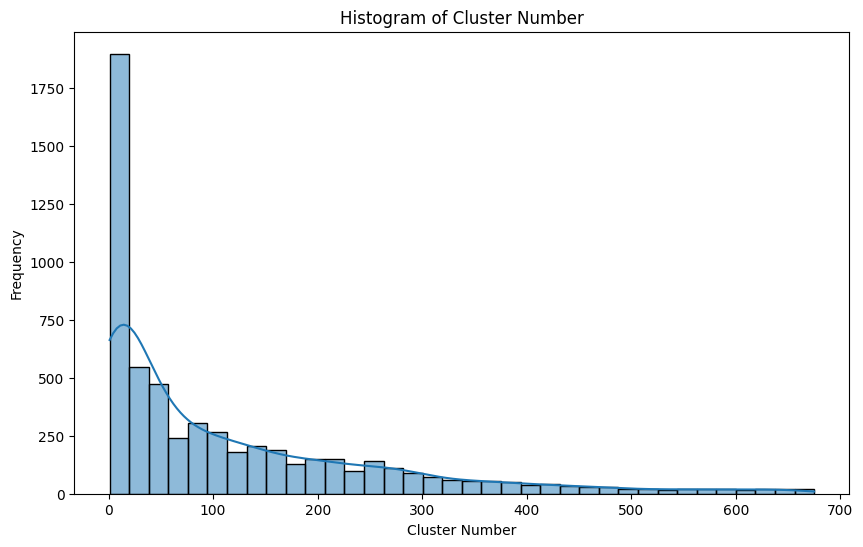

In [45]:
fig = px.scatter(df_d, x="Cluster_number", y="pChEMBL Value", color='Activity',
                 title="Activity vs. Cluster Number",
                 width=1000, height=750)

fig.update_layout(plot_bgcolor="white",  # Set plot background color
                  paper_bgcolor="white")   # Set paper background color
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_traces(marker=dict(size=12)) # Increase marker size
fig.update_layout(hoverlabel_font_size=20)

app_marker = molplotly.add_molecules(fig=fig,
                                     df=df_d,
                                     smiles_col='SMILES',
                                     #title_col='Cmpd',
                                     color_col='Activity',
                                     #caption_cols=['Cmpd'],
                                     fontsize=15, width=220)

# Assuming df_d is already created as in your provided code
plt.figure(figsize=(10, 6))  # Adjust figure size as needed
sns.histplot(df_d['Cluster_number'], kde=True)  # kde=True adds a kernel density estimate
plt.title('Histogram of Cluster Number')
plt.xlabel('Cluster Number')
plt.ylabel('Frequency')

#fig.show()
app_marker.run(port=8060)
plt.show()

In [46]:
# prompt: en dp_ACHE haz nueva colomna que se llame act_str donde le pondrás activo si tienen 1 en la columna 'activity' o 'sin actividad' si tienen 0

dp_ACHE['act_str'] = dp_ACHE['Activity'].apply(lambda x: 'Activo' if x == 1 else 'Sin actividad')
dp_ACHE.head()

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,Structure,act_str
0,0.795789,243.350,2.77350,18,2,20.31,2,0,1.0,CN1CCC(CC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a977a2d0>,Activo
1,0.834365,271.404,3.55370,20,4,20.31,2,0,1.0,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a977b7d0>,Activo
2,0.422541,208.281,2.11702,15,2,26.30,2,0,0.0,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779fc0>,Sin actividad
3,0.603594,405.542,4.50920,30,6,41.74,5,0,1.0,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779e70>,Activo
4,0.805692,236.267,2.08730,17,3,44.76,4,0,1.0,COc1cc2c(c(OC)c1OC)C(=O)C(C)C2,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779e00>,Activo


In [47]:
#dp_ACHE = dp_ACHE[dp_ACHE[act_str]]

In [48]:
fig4 = px.scatter_matrix(dp_ACHE,color='Activity',
                        dimensions=['MolWt','LogP', 'RB' ,'QED']
                        )
#fig.update_traces(diagonal_visible=False)

app_marker = molplotly.add_molecules(fig=fig4,
                                     #_____________dataframe___________________
                                     df=dp_ACHE,
                                     #__________________________________________
                                     smiles_col='SMILES',
#                                    title_col='Cmpd',
                                     #_____________color_________________________

                                     color_col='Activity',
                                     #_________________________________________
                                   # fontsize=20, width=350,
                                     #caption_cols=['TPSA','RB', 'HBA','HDB'],
                                     #show_coords=True
                                     )
app_marker.run(port=8060)

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

In [49]:
df_d.head()

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,Structure,Molecule ChEMBL ID,pChEMBL Value,Molecule Name,Cluster_number,cn_s,cn
0,0.795789,243.350,2.77350,18,2,20.31,2,0,1.0,CN1CCC(CC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a977a2d0>,CHEMBL345905,8.11,NaN,8,Cluster 8,8
1,0.834365,271.404,3.55370,20,4,20.31,2,0,1.0,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a977b7d0>,CHEMBL263322,8.82,NaN,104,Cluster 104,104
2,0.422541,208.281,2.11702,15,2,26.30,2,0,0.0,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779fc0>,CHEMBL338492,5.27,NaN,282,Cluster 282,282
3,0.603594,405.542,4.50920,30,6,41.74,5,0,1.0,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779e70>,CHEMBL93936,9.10,NaN,44,Cluster 44,44
4,0.805692,236.267,2.08730,17,3,44.76,4,0,1.0,COc1cc2c(c(OC)c1OC)C(=O)C(C)C2,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779e00>,CHEMBL440185,7.88,NaN,204,Cluster 204,204


In [50]:
df_d.to_excel('AZH.xlsx')

In [51]:
dp_ACHE.head()

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,Structure,act_str
0,0.795789,243.350,2.77350,18,2,20.31,2,0,1.0,CN1CCC(CC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a977a2d0>,Activo
1,0.834365,271.404,3.55370,20,4,20.31,2,0,1.0,CN1CCC(CCCC2Cc3ccccc3C2=O)CC1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a977b7d0>,Activo
2,0.422541,208.281,2.11702,15,2,26.30,2,0,0.0,CC(=O)Oc1ccc(C)c([N+](C)(C)C)c1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779fc0>,Sin actividad
3,0.603594,405.542,4.50920,30,6,41.74,5,0,1.0,c1ccc(CN2CCC(CCc3noc4cc(N5CCOCC5)ccc34)CC2)cc1,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779e70>,Activo
4,0.805692,236.267,2.08730,17,3,44.76,4,0,1.0,COc1cc2c(c(OC)c1OC)C(=O)C(C)C2,<rdkit.Chem.rdchem.Mol object at 0x7ad1a9779e00>,Activo


In [52]:
figa = px.scatter(dp_ACHE, x='MolWt', y='LogP', color='Activity', color_continuous_scale=['blue', 'green'])

# Set background color to white
figa.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#figa.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
figa.update_layout(hoverlabel_font_size=20)
#figa.update_layout(showlegend=False) # This line removes the legend
#figa.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
#figa.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
figa.update_traces(marker=dict(size=4)) # Increase marker size

app_marker = molplotly.add_molecules(fig=figa,
                                     #_____________dataframe___________________
                                     df=dp_ACHE,
                                     #__________________________________________
                                     smiles_col='SMILES',
#                                    title_col='Cmpd',
                                     #_____________color_________________________

                                     color_col='Activity',
                                     #_________________________________________
                                    fontsize=20, width=350,
                                     #caption_cols=['TPSA'],
                                     #show_coords=False
                                           )
app_marker.run(port=8060)
#fig.show()

/usr/local/lib/python3.13/dist-packages/dash/dash.py:634: UserWarning:

JupyterDash is deprecated, use Dash instead.
See https://dash.plotly.com/dash-in-jupyter for more details.



<IPython.core.display.Javascript object>

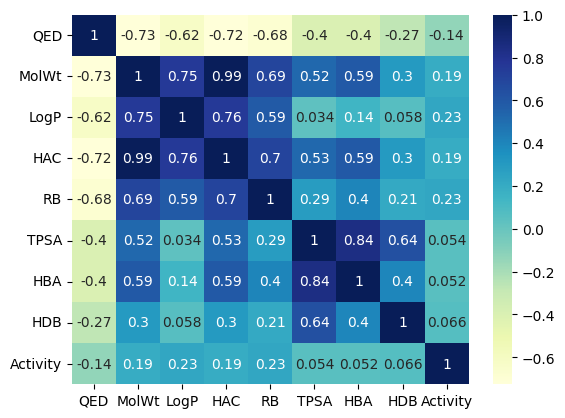

In [53]:
# prompt: de dp_ACHE elimina las columnas SMILES y act_str
dp_ACHE = dp_ACHE.drop(columns=['SMILES', 'act_str','Structure'])

# plotting correlation heatmap
dataplot = sns.heatmap(dp_ACHE.corr(), cmap="YlGnBu", annot=True)

# displaying heatmap
plt.show()

Podemos notar que existe una alta correlación entre el número de átomos pesados ​​y la masa molecular. Por lo tanto, eliminaremos este descriptor de nuestro conjunto de datos.

In [54]:
dp_ACHE.drop(labels='HAC', axis=1, inplace=True)
#dp_ACHE

## Escalamiento

In [55]:
from sklearn.model_selection import train_test_split  # Para dividir dados em treino/teste

# split data in 80:20 for train:test dataset
X = dp_ACHE.iloc[:, :-1]  # Todas as linhas, todas as colunas exceto a última
y = dp_ACHE.iloc[:, -1]   # Todas as linhas, apenas a última coluna (target)

# In the first step we will split the data in training and remaining dataset
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)


print(X_train.shape), print(y_train.shape)
print(X_test.shape), print(y_test.shape)

(4663, 7)
(4663,)
(1166, 7)
(1166,)


(None, None)

Es importante señalar que los valores tienen escalas muy diferentes; por ejemplo, `MolWt` está en centenas, mientras que `NumHDonors` está en decenas. Para evitar que esto cause __sesgo__ en la predicción, escalaremos los valores.

In [56]:
from sklearn.preprocessing import *

# Definimos el escalador
sc = StandardScaler()

# Definimos las matrices  x_train y x_y
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
print(X_test)

[[ 1.60528473e+00 -6.32929454e-01 -2.06108866e-01 ... -1.83440951e-03
  -2.18709434e-01  7.40724208e-01]
 [ 5.65714200e-01 -1.23327010e-01 -6.47931853e-01 ...  3.95084212e-01
  -2.18709434e-01 -1.01882596e+00]
 [-1.69975242e+00  1.78247069e+00  2.64183832e+00 ...  3.35737859e-01
   1.31411936e+00 -1.39050877e-01]
 ...
 [-1.14079326e+00  5.40696738e-01  1.11351789e+00 ...  4.65597890e-01
   8.03176427e-01 -1.39050877e-01]
 [-7.57492313e-01  9.68619826e-02  6.68799204e-01 ... -4.40550731e-01
  -7.29652364e-01 -1.39050877e-01]
 [ 6.74209879e-02  1.44779136e-01 -3.28022952e-01 ... -1.80830669e-01
   8.03176427e-01 -1.01882596e+00]]


# Entrenando un modelo Random Forest

In [57]:
# Definimos el clasificador
classifier = RandomForestClassifier(n_estimators=120, random_state=0, min_samples_split=4, #min_samples_leaf=3
                                    )
# Ajustamos el clasificador
classifier.fit(X_train, y_train)
# Realizamos las predicciones
x_pred = classifier.predict(X_test)
# contamos los valores
pd.DataFrame(x_pred).value_counts()

,count
0,
0.0,805
1.0,361


thresh: 0.50, kappa: 0.507, AUC test-set: 0.744
[[621  81]
 [184 280]]
              precision    recall  f1-score   support

         0.0      0.771     0.885     0.824       702
         1.0      0.776     0.603     0.679       464

    accuracy                          0.773      1166
   macro avg      0.774     0.744     0.751      1166
weighted avg      0.773     0.773     0.766      1166

None


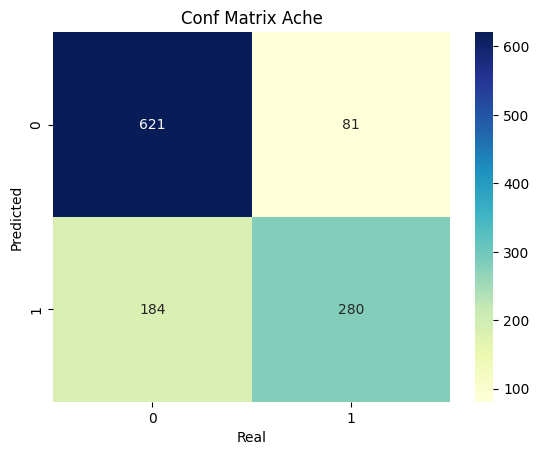

In [58]:
print (calc_metrics(y_test, x_pred))

sns.heatmap(confusion_matrix(y_test, x_pred),cmap='YlGnBu' ,annot=True,fmt='2.0f')
plt.title('Conf Matrix Ache')
plt.ylabel('Predicted')
plt.xlabel('Real')
plt.show()

# Entrenando un modelo basado en Huellas dactilares (fingerprints)

Creemos una función para calcular las huellas dactilares de Morgan usando la biblioteca RDKit.

In [59]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      fp_ACHE = calcula_fp1(smiles_ache_stand)
      pbar.update(100)
fp_ACHE

  0%|          | 0/100 [00:00<?, ?it/s]

,0,1,2,3,4,5,6,7,8,9,...,2038,2039,2040,2041,2042,2043,2044,2045,2046,2047
result0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
result1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
result2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
result3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
result4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
result5824,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
result5825,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
result5826,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
result5827,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [60]:
# Resetar índices antes de atribuir
fp_ACHE = fp_ACHE.reset_index(drop=True)
resultado = resultado.reset_index(drop=True)
fp_ACHE['Activity'] = resultado['Activity']
fp_ACHE

,0,1,2,3,4,5,6,7,8,9,...,2039,2040,2041,2042,2043,2044,2045,2046,2047,Activity
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5824,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5825,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5826,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
5827,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [61]:
# split data in 80:20 for train:test dataset
X = fp_ACHE.iloc[:, :-1]  # Todas as linhas, todas as colunas exceto a última
y = fp_ACHE.iloc[:, -1]   # Todas as linhas, apenas a última coluna (target)

# In the first step we will split the data in training and remaining dataset
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

print(X_train.shape), print(y_train.shape)
print(X_test.shape), print(y_test.shape)

(4663, 2048)
(4663,)
(1166, 2048)
(1166,)


(None, None)

In [62]:
classifier = RandomForestClassifier(random_state=0, n_estimators=90
                                    )

classifier.fit(X_train, y_train)
x_pred = classifier.predict(X_test)

thresh: 0.50, kappa: 0.675, AUC test-set: 0.827
[[657  45]
 [131 333]]
              precision    recall  f1-score   support

         0.0      0.834     0.936     0.882       702
         1.0      0.881     0.718     0.791       464

    accuracy                          0.849      1166
   macro avg      0.857     0.827     0.836      1166
weighted avg      0.853     0.849     0.846      1166

None


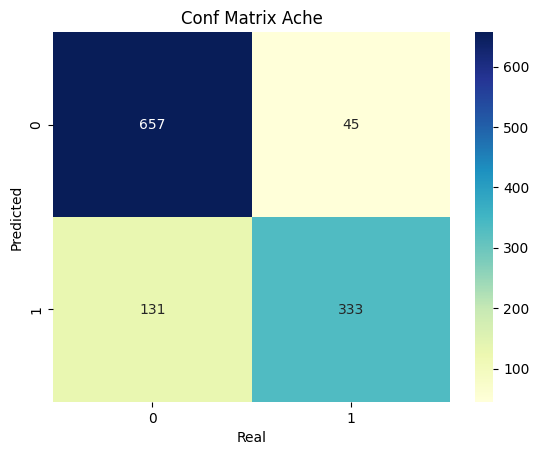

In [63]:
print (calc_metrics(y_test, x_pred))

sns.heatmap(confusion_matrix(y_test, x_pred),cmap='YlGnBu' ,annot=True,fmt='2.0f')
plt.title('Conf Matrix Ache')
plt.ylabel('Predicted')
plt.xlabel('Real')
plt.show()

# Entrenamos un modelo basado ChEMBERTA

In [64]:
from transformers import AutoTokenizer, AutoModelForMaskedLM
import torch
from tqdm import tqdm  # Para barra de progresso


# 1. Cargar modelos y tokenizador
tokenizer = AutoTokenizer.from_pretrained("DeepChem/ChemBERTa-77M-MLM")
model = AutoModelForMaskedLM.from_pretrained("DeepChem/ChemBERTa-77M-MLM")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# 2. Funión para generar embeddings
def get_molecule_embedding(smiles, model, tokenizer):
    inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
    with torch.no_grad():
        outputs = model(**inputs, output_hidden_states=True)
        last_hidden_state = outputs.hidden_states[-1]
        #return last_hidden_state[:,0,:].squeeze().cpu().numpy() #get the first row of embedding (classification token)
        return last_hidden_state.mean(dim=1).squeeze().cpu().numpy() #average values

# 3. Procesar todos los SMILES (con barra de progreso)
embeddings = []
failed_smiles = []

for smile in tqdm(smiles_ache_stand, desc="Generando embeddings"):
    try:
        if pd.isna(smile) or not smile:  # Pula valores nulos/vazios
            continue
        emb = get_molecule_embedding(smile, model, tokenizer)
        embeddings.append(emb)
    except Exception as e:
        failed_smiles.append(smile)
        continue

# 4. Converter para DataFrame
df_embeddings = pd.DataFrame(embeddings)
#df_embeddings['SMILES'] = [s for s in smiles_ache_stand if s not in failed_smiles]
df_embeddings['Activity'] = resultado['Activity']
print(f"\nEmbeddings gerados: {len(embeddings)}")
print(f"SMILES falhados: {len(failed_smiles)}")
print(f"Shape dos embeddings: {df_embeddings.shape}")

config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.96k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.26k [00:00<?, ?B/s]

...

Generando embeddings:   0%|          | 1/5829 [00:00<20:41,  4.70it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 13.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Generando embeddings: 100%|██████████| 5829/5829 [01:28<00:00, 65.98it/s]



Embeddings gerados: 5829
SMILES falhados: 0
Shape dos embeddings: (5829, 385)


In [65]:
df_embeddings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5829 entries, 0 to 5828
Columns: 385 entries, 0 to Activity
dtypes: float32(384), float64(1)
memory usage: 8.6 MB


In [66]:
# split data in 80:20 for train:test dataset
X = df_embeddings.iloc[:, :-1]  # Todas as linhas, todas as colunas exceto a última
y = df_embeddings.iloc[:, -1]   # Todas as linhas, apenas a última coluna (target)

# In the first step we will split the data in training and remaining dataset
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

print(X_train.shape), print(y_train.shape)
print(X_test.shape), print(y_test.shape)

(4663, 384)
(4663,)
(1166, 384)
(1166,)


(None, None)

thresh: 0.50, kappa: 0.591, AUC test-set: 0.782
[[655  47]
 [171 293]]
              precision    recall  f1-score   support

         0.0      0.793     0.933     0.857       702
         1.0      0.862     0.631     0.729       464

    accuracy                          0.813      1166
   macro avg      0.827     0.782     0.793      1166
weighted avg      0.820     0.813     0.806      1166

None


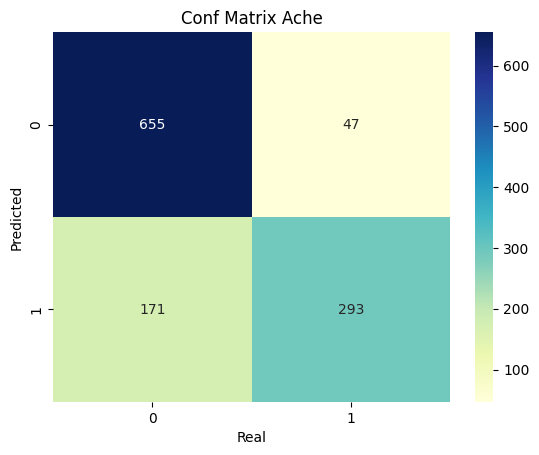

In [67]:
classifier = RandomForestClassifier(random_state=0, n_estimators=100)

classifier.fit(X_train, y_train)
x_pred = classifier.predict(X_test)

print (calc_metrics(y_test, x_pred))

sns.heatmap(confusion_matrix(y_test, x_pred),cmap='YlGnBu' ,annot=True,fmt='2.0f')
plt.title('Conf Matrix Ache')
plt.ylabel('Predicted')
plt.xlabel('Real')
plt.show()


thresh: 0.50, kappa: 0.658, AUC test-set: 0.819
[[653  49]
 [136 328]]
              precision    recall  f1-score   support

         0.0      0.828     0.930     0.876       702
         1.0      0.870     0.707     0.780       464

    accuracy                          0.841      1166
   macro avg      0.849     0.819     0.828      1166
weighted avg      0.845     0.841     0.838      1166
